# Google Developer Group - Taif University (Task 1)

By : Saad Almalki / 0xSaad

### Importing libraries :

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
df1 = pd.read_csv("data/index1.csv")
df2 = pd.read_csv("data/index2.csv")

df1.columns = df1.columns.str.lower()

### Checking data :

In [3]:
df1.head()

,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte


### Feature engineering

In [4]:
df = df1.copy()

df.columns = df.columns.str.strip().str.lower()

In [5]:
df["money"] = pd.to_numeric(df["money"], errors="coerce")


if "datetime" in df.columns:
    df["datetime"] = pd.to_datetime(
        
        df["datetime"], errors="coerce"
        
    )



else:
    df["datetime"] = pd.to_datetime(
        df["date"].astype(str) + " " + df["time"].astype(str),
        errors="coerce"
        
    )


df["hour"] = df["datetime"].dt.hour
df["weekday"] = df["datetime"].dt.day_name()
df["day"] = df["datetime"].dt.date
df["month"] = df["datetime"].dt.to_period("M")


In [6]:
display(df.head())

,date,datetime,cash_type,card,money,coffee_name,hour,weekday,day,month
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte,10,Friday,2024-03-01,2024-03
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate,12,Friday,2024-03-01,2024-03
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate,12,Friday,2024-03-01,2024-03
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano,13,Friday,2024-03-01,2024-03
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte,13,Friday,2024-03-01,2024-03


### Dataset overview  :


In [7]:
print("shape of dataset :", df.shape)
print("Total records : ", len(df))
print("Start date :", df["datetime"].min())
print("End date : ", df["datetime"].max())
print("Unique days : ", df["day"].nunique())

shape of dataset : (3636, 10)
Total records :  3636
Start date : 2024-03-01 10:15:50.520000
End date :  2025-03-23 18:11:38.635000
Unique days :  381


### Data quality check :

In [8]:
df.info()

print("\n Missing Values:")
display(df.isna().sum())

print("\n Duplicated Rows:", df.duplicated().sum())
print("\n Money Data Type:", df["money"].dtype)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3636 entries, 0 to 3635
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         3636 non-null   object        
 1   datetime     3636 non-null   datetime64[ns]
 2   cash_type    3636 non-null   object        
 3   card         3547 non-null   object        
 4   money        3636 non-null   float64       
 5   coffee_name  3636 non-null   object        
 6   hour         3636 non-null   int32         
 7   weekday      3636 non-null   object        
 8   day          3636 non-null   object        
 9   month        3636 non-null   period[M]     
dtypes: datetime64[ns](1), float64(1), int32(1), object(6), period[M](1)
memory usage: 270.0+ KB

 Missing Values:


date            0
datetime        0
cash_type       0
card           89
money           0
coffee_name     0
hour            0
weekday         0
day             0
month           0
dtype: int64


 Duplicated Rows: 0

 Money Data Type: float64


### Descriptive Statistics

In [9]:
print("Money Statistics:")
display(df["money"].describe().round(2))

print("\n")
print("Coffee sales :")
display(df["coffee_name"].value_counts())


print("\n")
print("Top 2 drinks :")
display(df["coffee_name"].value_counts().head(2))

Money Statistics:


count    3636.00
mean       31.75
std         4.92
min        18.12
25%        27.92
50%        32.82
75%        35.76
max        40.00
Name: money, dtype: float64



Coffee sales :


coffee_name
Americano with Milk    824
Latte                  782
Americano              578
Cappuccino             501
Cortado                292
Hot Chocolate          282
Cocoa                  243
Espresso               134
Name: count, dtype: int64



Top 2 drinks :


coffee_name
Americano with Milk    824
Latte                  782
Name: count, dtype: int64

### visualizations :

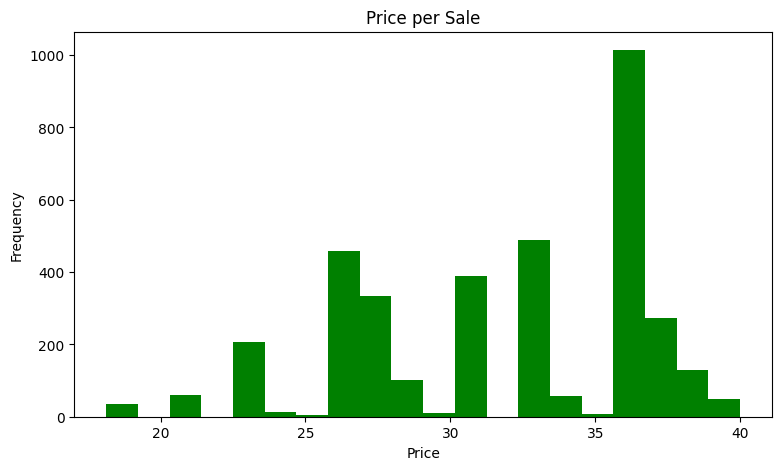

In [10]:
df["money"].plot(
    kind="hist",
    color="green",
    bins=20,
    figsize=(9, 5),
    title="Price per Sale"
)

plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

Text(0, 0.5, 'Coffee Name')

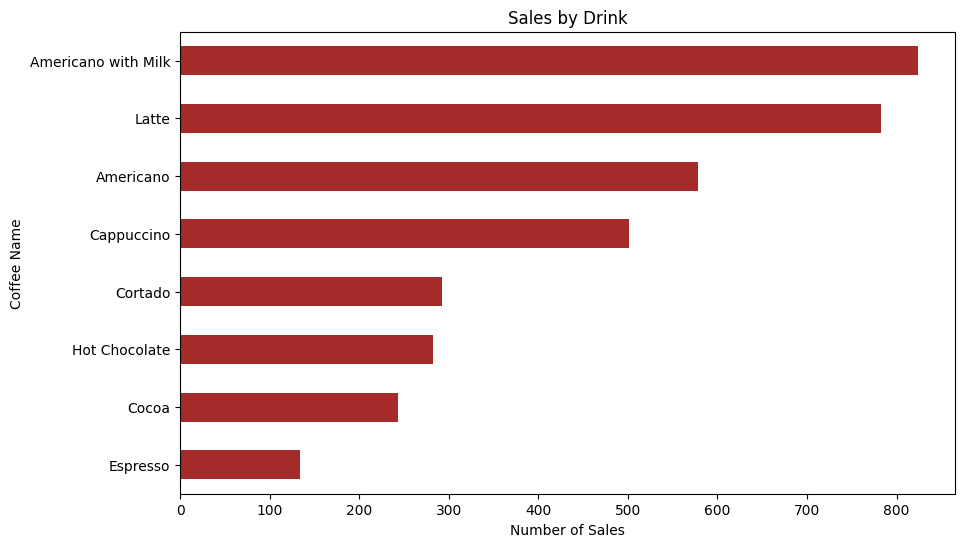

In [11]:
counts = df["coffee_name"].value_counts()

counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Sales by Drink",
    color="brown"
    
)

plt.xlabel("Number of Sales")
plt.ylabel("Coffee Name")


In [12]:
plt.show()

### Daily Performance Indicators

In [13]:
daily = df.groupby("day").agg(
    revenue=("money", "sum"),
    sales=("money", "count")
)

daily["avg_ticket"] = daily["revenue"] / daily["sales"]

display(daily.describe().round(2))

,revenue,sales,avg_ticket
count,381.00,381.00,381.00
mean,302.97,9.54,31.93
std,159.82,5.10,2.91
min,23.02,1.00,21.39
25%,187.12,6.00,30.25
50%,276.28,9.00,32.26
75%,389.92,12.00,33.96
max,836.66,26.00,39.35


### product performance :

In [14]:
prod = df.groupby("coffee_name").agg(
    sales=("money", "count"),
    revenue=("money", "sum"),
    avg_price=("money", "mean")
)

prod["share_%"] = prod["revenue"] / prod["revenue"].sum() * 100

display(prod.sort_values("revenue", ascending=False).round(1))

,sales,revenue,avg_price,share_%
coffee_name,,,,
Latte,782,27866.3,35.6,24.1
Americano with Milk,824,25269.1,30.7,21.9
Cappuccino,501,18034.1,36.0,15.6
Americano,578,15062.3,26.1,13.0
Hot Chocolate,282,10172.5,36.1,8.8
Cocoa,243,8678.2,35.7,7.5
Cortado,292,7534.9,25.8,6.5
Espresso,134,2814.3,21.0,2.4


### Sales analysis by hours :

In [15]:
by_hour = df.groupby("hour").agg(
    
    sales=("money", "count"),
    revenue=("money", "sum")
    
)

display(by_hour)


,sales,revenue
hour,,
6,5,149.40
7,91,2940.02
8,235,7017.88
9,247,7429.28
10,349,10994.52
11,294,8849.10
12,249,7668.62
13,227,7108.76
14,228,7265.80


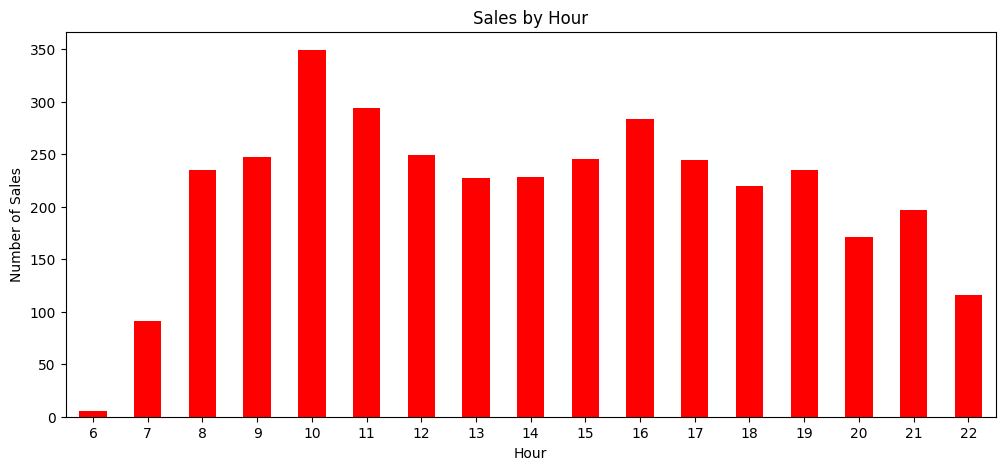

In [16]:
by_hour["sales"].plot(
    kind="bar",
    color="red",
    figsize=(12, 5),
    title="Sales by Hour"
)

plt.xlabel("Hour")
plt.ylabel("Number of Sales")
plt.xticks(rotation=0)

plt.show()

### Analysis within weeks

#### Days in week :

In [17]:
daysorder = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday
Monday       17925.10
Tuesday      18637.38
Wednesday    16093.46
Thursday     16477.40
Friday       17257.66
Saturday     15182.52
Sunday       13858.06
Name: money, dtype: float64

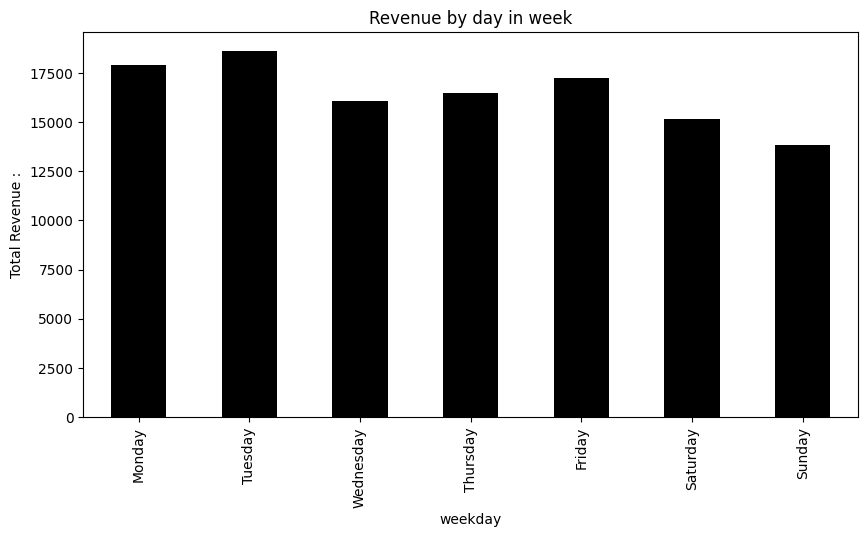

In [18]:
by_day = (
    df.groupby("weekday")["money"]
    .sum()
    .reindex(daysorder)
)

display(by_day.round(2))

by_day.plot(
    kind="bar",
    color="black",
    figsize=(10, 5),
    title="Revenue by day in week"
    
)

plt.ylabel("Total Revenue :")
plt.show()

### Sales analysis by months :

In [19]:
by_month = df.groupby("month")["money"].sum()

display(by_month.round(2))

month
2024-03     7050.20
2024-04     6720.56
2024-05     9063.42
2024-06     7758.76
2024-07     6915.94
2024-08     7613.84
2024-09     9988.64
2024-10    13891.16
2024-11     8590.54
2024-12     8237.74
2025-01     6398.86
2025-02    13215.48
2025-03     9986.44
Freq: M, Name: money, dtype: float64

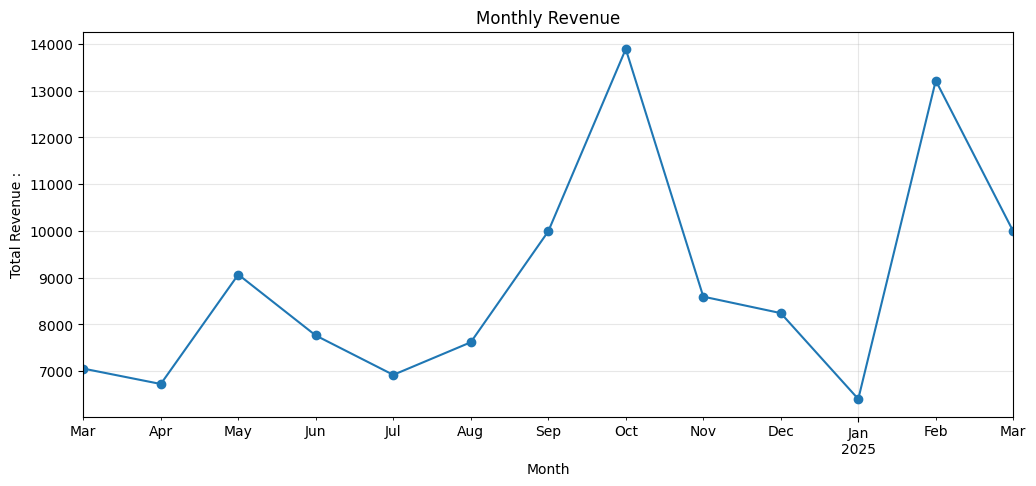

In [20]:
by_month.plot(
    kind="line",
    marker="o",
    figsize=(12, 5),
    title="Monthly Revenue"
)

plt.xlabel("Month")
plt.ylabel("Total Revenue :")
plt.grid(alpha=0.3)
plt.show()

#### Time periods in day

In [21]:
df["period"] = pd.cut(
    df["hour"],
    bins=[0, 12, 17, 24],
    labels=["Morning", "Afternoon", "Evening"],
    right=False
)

mix = pd.crosstab(
    df["coffee_name"],
    df["period"],
    normalize="columns"
) * 100

display(mix.round(2))

period,Morning,Afternoon,Evening
coffee_name,,,
Americano,18.43,19.40,9.64
Americano with Milk,27.52,19.81,20.63
Cappuccino,10.32,13.72,17.41
Cocoa,4.83,6.25,9.04
Cortado,11.88,7.39,4.73
Espresso,3.77,4.71,2.54
Hot Chocolate,4.10,6.66,12.68
Latte,19.16,22.08,23.33


### Peak vs Quite times

In [22]:
busy_hour = by_hour["sales"].idxmax()
quiet_hour_raw = by_hour["sales"].idxmin()
top_drink = prod["revenue"].idxmax()

print("Busiest Hour:", busy_hour)
print("Quietest Hour (Overall):", quiet_hour_raw)
print("Top Revenue Drink:", top_drink)

Busiest Hour: 10
Quietest Hour (Overall): 6
Top Revenue Drink: Latte


### Notes :

- I used index1 for the analysis. It has 3636 rows and 6 original columns, and 10 columns after adding the time features. The data is from 2024-03-01 to 2025-03-23, with 381 days that have sales.
- There are 89 missing values in card, all for cash payments, so I kept those rows. money is float64, which lets us calculate totals and averages. There are no duplicated rows.
- The average sale is 31.75 and the median is 32.82. Americano with Milk is the most sold drink with 824 sales, followed by Latte with 782.
- Prices are grouped around certain values. Espresso is the least sold drink with 134 sales.
- Average daily revenue is 302.97, with 9.54 sales per recorded day. These are the daily baseline numbers.
- Latte has the highest revenue, while Americano with Milk has the most sales. I would avoid choosing Latte for a discount just because its revenue is highest, since it already sells well.
- The busiest hour is 10:00 with 349 sales. 06:00 has only 5 sales, so I would not choose it only because it is the lowest. 20:00 has 171 sales, fewer than 19:00 and 21:00, but still has customers.
- Sunday has the lowest total revenue. Monthly revenue goes up and down, with the highest total in October 2024 and another high month in February 2025. March 2025 only includes data until the 23rd, so it is not a full-month comparison.
- In the evening, Latte is the most popular drink at about 23.3%. Cocoa has about 9.0% of evening sales, so it has some demand without being the top revenue drink.
- I would test a Cocoa discount from 20:00 to 21:00, after confirming the machine is open then. Compare sales and revenue in that hour with similar days before the offer, and check the margin after the discount before deciding to continue.


In [23]:
ANALYST = "Saad Almalki / 0xSaad"
RECOMMENDATION = (
    "Test a Cocoa discount from 20:00 to 21:00, after confirming opening hours, "
    "because 20:00 has fewer sales than the nearby hours and Cocoa has evening demand. "
    "Compare sales, revenue and margin with similar days before the offer."
)

from datetime import date

print("=" * 55)
print("DECISION MEMO")
print("=" * 55)
print("Dataset  : Coffee Sales (Kaggle: ihelon/coffee-sales)")
print("Period   :", df["day"].min(), "->", df["day"].max())
print(f"Sales    : {len(df):,} | Revenue: {df['money'].sum():,.0f}")
print(f"Daily avg: {daily['revenue'].mean():,.1f}")
print(f"Peak hour: {busy_hour}:00 | Quiet hour (Overall): {quiet_hour_raw}:00")
print("Top drink:", top_drink)
print("-" * 55)
print("Recommendation:", RECOMMENDATION)
print("-" * 55)
print("Prepared by:", ANALYST, "| Data Scientist")
print("GDGoC Taif University |", date.today())
print("=" * 55)

DECISION MEMO
Dataset  : Coffee Sales (Kaggle: ihelon/coffee-sales)
Period   : 2024-03-01 -> 2025-03-23
Sales    : 3,636 | Revenue: 115,432
Daily avg: 303.0
Peak hour: 10:00 | Quiet hour (Overall): 6:00
Top drink: Latte
-------------------------------------------------------
Recommendation: Test a Cocoa discount from 20:00 to 21:00, after confirming opening hours, because 20:00 has fewer sales than the nearby hours and Cocoa has evening demand. Compare sales, revenue and margin with similar days before the offer.
-------------------------------------------------------
Prepared by: Saad Almalki / 0xSaad | Data Scientist
GDGoC Taif University | 2026-11-04
